# High-rate stairway codes — logical error rate vs p

Curves of logical error rate vs physical error rate `p` for each `[[n,k,d]]` stairway code in the
`threshold_stairway` collection (decoded with the Tesseract decoder)."""

In [4]:
import ast
import datetime
import glob
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sinter

In [5]:
CSV_GLOB = '../out/collection/threshold_stairway,*.csv'

BIAS = 10

files = sorted(glob.glob(CSV_GLOB))
if not files:
    raise FileNotFoundError(f'No files matched: {CSV_GLOB}')

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)


def _parse_custom_counts(s):
    if not isinstance(s, str) or s == 'Counter()':
        return {}
    m = re.search(r"Counter\(\{(.+)\}\)", s)
    if not m:
        return {}
    return {k: int(v) for k, v in re.findall(r"'(\w+)':\s*(\d+)", m.group(1))}


if 'custom_counts' in df.columns:
    counts = df['custom_counts'].apply(_parse_custom_counts)
    df['low_confidence_shots'] = counts.apply(lambda c: c.get('low_confidence_shots', 0))
else:
    df['low_confidence_shots'] = 0

# Merge repeated runs by strong_id (same circuit + decoder).
df = df.groupby('strong_id').agg({
    'shots': 'sum',
    'errors': 'sum',
    'discards': 'sum',
    'seconds': 'sum',
    'low_confidence_shots': 'sum',
    'decoder': 'first',
    'json_metadata': 'first',
}).reset_index()

meta = df['json_metadata'].apply(lambda s: ast.literal_eval(s) if isinstance(s, str) else dict(s))
df['p'] = meta.apply(lambda m: m.get('p'))
df['p_bell_z'] = meta.apply(lambda m: m.get('p_bell_z'))
df['bias'] = meta.apply(lambda m: m.get('bias'))

# Stairway sidecar metadata carries n / k / expected_distance directly
# (it's propagated by make_threshold_circuits_bell.py). Fall back to
# parsing the input-circuit filename for the hyperbolic naming scheme.
_NKD = re.compile(r'n=(\d+)_k=(\d+)_d=(\d+)')
def _nkd(m):
    n = m.get('n')
    k = m.get('k')
    d = m.get('expected_distance', m.get('d'))
    if n is not None and k is not None and d is not None:
        return (int(n), int(k), int(d))
    mm = _NKD.search(m.get('input_circuit', ''))
    if not mm:
        return (None, None, None)
    return tuple(int(x) for x in mm.groups())

df[['n', 'k', 'd']] = pd.DataFrame(meta.apply(_nkd).tolist(), index=df.index)
df['code'] = df.apply(lambda r: f"[[{r['n']},{r['k']},{r['d']}]]", axis=1)

df['pL'] = df['errors'] / df['shots'].clip(lower=1)
df['pL_err'] = np.sqrt(np.clip(df['pL'] * (1 - df['pL']), 0, None) / df['shots'].clip(lower=1))

available_biases = sorted(df['bias'].dropna().unique())
df = df[np.isclose(df['bias'].astype(float), float(BIAS))].reset_index(drop=True)
if df.empty:
    raise ValueError(f'no rows for BIAS={BIAS}; available biases: {available_biases}')

code_order = (
    df.drop_duplicates('code')
      .sort_values('n')['code']
      .tolist()
)
n_zero = int((df['errors'] == 0).sum())
print(f'{len(df)} rows; bias={BIAS:g} (available: {available_biases}); codes={code_order}')
print(f'zero-error rows kept: {n_zero}/{len(df)} (sinter draws them as upper bounds)')
print(f'low-confidence shots: {int(df["low_confidence_shots"].sum())} / {int(df["shots"].sum())} total')
df.head()

24 rows; bias=10 (available: [np.float64(10.0)]); codes=['[[192,16,4]]', '[[192,6,9]]', '[[288,14,10]]']
zero-error rows kept: 10/24 (sinter draws them as upper bounds)
low-confidence shots: 19 / 19452 total


,strong_id,shots,errors,discards,seconds,low_confidence_shots,decoder,json_metadata,p,p_bell_z,bias,n,k,d,code,pL,pL_err
0,0410f8e74d02f34f2220d1e7151c254c4e7aa54295d5ee...,1000,1,0,142.536139,0,tesseract_short,"{'p': 0.00018478497974222906, 'rounds': -1, 'n...",0.000185,0.001848,10.0,288,14,10,"[[288,14,10]]",0.001,0.000999
1,0755dcfffbe3ca22b4f03c162a38fd61384a69c7783a12...,1000,0,0,78.392646,0,tesseract_short,"{'p': 0.0003414548873833601, 'rounds': -1, 'no...",0.000341,0.003415,10.0,192,16,4,"[[192,16,4]]",0.000,0.000000
2,0af0af0f931d88810fc905cfa8eb59225d68922e1ccc18...,2000,0,0,84.845310,0,tesseract_short,"{'p': 0.0001, 'rounds': -1, 'noise_model': 'bi...",0.000100,0.001000,10.0,288,14,10,"[[288,14,10]]",0.000,0.000000
3,3bd8edff74844b56175af9107bf8ef2100f8b1acf74e53...,2000,0,0,34.618450,0,tesseract_short,"{'p': 0.0001, 'rounds': -1, 'noise_model': 'bi...",0.000100,0.001000,10.0,192,6,9,"[[192,6,9]]",0.000,0.000000
4,4fd1e6da535f9414f441b9078ba026f65f80900a8d9b53...,1000,5,0,1384.259459,0,tesseract_short,"{'p': 0.0003414548873833601, 'rounds': -1, 'no...",0.000341,0.003415,10.0,288,14,10,"[[288,14,10]]",0.005,0.002230


Saved ../out/figures/20260625_high_rate_stairway_bias10.pdf


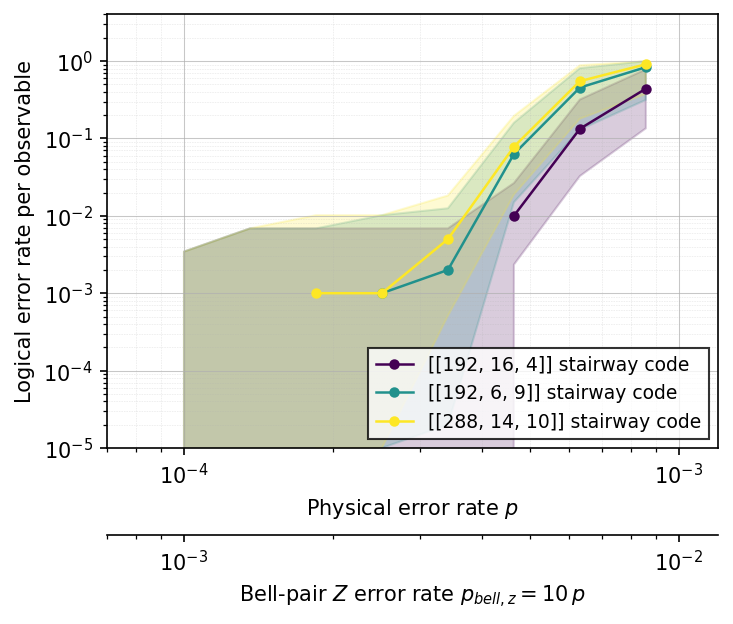

In [6]:
plt.rcParams.update({
    'font.size': 10,
    'axes.labelsize': 10,
    'axes.titlesize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
})

cmap = plt.get_cmap('viridis')
colors = {code: cmap(i / max(1, len(code_order) - 1)) for i, code in enumerate(code_order)}


def _meta(row):
    m = ast.literal_eval(row['json_metadata']) if isinstance(row['json_metadata'], str) else dict(row['json_metadata'])
    m['n'] = int(row['n'])
    m['k'] = int(row['k'])
    m['expected_distance'] = int(row['d'])
    return m


tasks = [
    sinter.TaskStats(
        strong_id=row['strong_id'],
        decoder=row['decoder'],
        json_metadata=_meta(row),
        shots=int(row['shots']),
        errors=int(row['errors']),
        discards=int(row['discards']),
        seconds=float(row['seconds']),
    )
    for _, row in df.iterrows()
]


def group_func(stat):
    n = stat.json_metadata['n']
    k = stat.json_metadata['k']
    d = stat.json_metadata['expected_distance']
    return f'[[{n}, {k}, {d}]] stairway code'


def plot_args_func(index, group_key, group_stats):
    # Strip the trailing " stairway code" suffix to look up the viridis color
    # by the [[n,k,d]] key from `code_order` (which has no spaces or suffix).
    key = group_key.split(']]')[0].replace(' ', '') + ']]'
    return {'color': colors.get(key, 'k'), 'marker': 'o', 'markersize': 4, 'linewidth': 1.2}


fig, ax = plt.subplots(1, 1, figsize=(5, 4))

sinter.plot_error_rate(
    ax=ax,
    stats=tasks,
    x_func=lambda s: s.json_metadata['p'],
    group_func=group_func,
    plot_args_func=plot_args_func,
    failure_units_per_shot_func=lambda s: 1,
    failure_values_func=lambda s: s.json_metadata['k'],
)

ax.loglog()

# Sort legend by n.
handles, labels = ax.get_legend_handles_labels()
def _extract_n(lbl):
    m = re.search(r'\[\[(\d+),', lbl)
    return int(m.group(1)) if m else 0
sorted_pairs = sorted(zip(handles, labels), key=lambda hl: _extract_n(hl[1]))
if sorted_pairs:
    sorted_handles, sorted_labels = zip(*sorted_pairs)
    ax.legend(sorted_handles, sorted_labels, loc='lower right',
              frameon=True, edgecolor='black', fancybox=False)

p_min = float(df['p'].min())
p_max = float(df['p'].max())
ax.set_xlim(p_min * 0.7, p_max * 1.4)
ax.set_ylim(1e-5, 4)

ax.set_xlabel(r'Physical error rate $p$')
ax.set_ylabel(r'Logical error rate per observable')
ax.grid(which='major', linestyle='-', linewidth=0.5, alpha=0.7)
ax.grid(which='minor', linestyle=':', linewidth=0.3, alpha=0.5)

# Second x-axis underneath, showing p_bell_z = BIAS * p.
fig.tight_layout()
fig.subplots_adjust(bottom=0.24)

ax_pbz = ax.secondary_xaxis(
    -0.20,
    functions=(lambda p: p * BIAS, lambda pbz: pbz / BIAS),
)
ax_pbz.set_xlabel(rf'Bell-pair $Z$ error rate $p_{{bell,z}} = {BIAS:g}\,p$')

fig.set_dpi(150)

out_dir = Path('../out/figures')
out_dir.mkdir(parents=True, exist_ok=True)
date = datetime.date.today().strftime('%Y%m%d')
out_path = out_dir / f'{date}_high_rate_stairway_bias{int(BIAS)}.pdf'
fig.savefig(out_path, bbox_inches='tight')
print(f'Saved {out_path}')
plt.show()